# S&P 500 vs Bitcoin — analiza historyczna

Notebook prezentuje porównanie **S&P 500 (`^GSPC`)** i **Bitcoina (`BTC-USD`)** na podstawie wyników zapisanych wcześniej w folderze `data/`.

Analizujemy:
- wzrost wartości początkowych 100 USD,
- roczną zmienność,
- Sharpe Ratio,
- Maximum Drawdown,
- korelację Pearsona i korelację kroczącą.

## Jak uruchomić?

1. Wykonaj wcześniejsze skrypty z katalogu głównego projektu, aby utworzyć pliki CSV w `data/`.
2. Otwórz ten notebook w VS Code lub Jupyterze.
3. Wybierz kernel z projektu (`.venv`) i użyj **Run All**.

Notebook zapisuje wykresy PNG do katalogu `charts/`.

In [33]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter
from IPython.display import display

ASSETS = ["SP500", "BTC"]
ASSET_LABELS = {"SP500": "S&P 500", "BTC": "Bitcoin"}


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "data" / "prices.csv").is_file():
            return candidate
    raise FileNotFoundError(
        "Nie znaleziono data/prices.csv. Uruchom notebook z projektu, "
        "w którym istnieje katalog data/ z plikami CSV."
    )

PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_DIR = PROJECT_ROOT / "data"
CHARTS_DIR = PROJECT_ROOT / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Katalog projektu: {PROJECT_ROOT}")
print(f"Dane: {DATA_DIR}")
print(f"Wykresy: {CHARTS_DIR}")

Katalog projektu: /home/lukaszmusial/programming/projekty/analysis-BTC-vs-spy-return
Dane: /home/lukaszmusial/programming/projekty/analysis-BTC-vs-spy-return/data
Wykresy: /home/lukaszmusial/programming/projekty/analysis-BTC-vs-spy-return/charts


In [34]:
def read_csv_required(filename: str, **kwargs) -> pd.DataFrame:
    """Wczytaj wymagany CSV albo pokaż czytelny komunikat o brakującym pliku."""
    path = DATA_DIR / filename
    if not path.is_file():
        raise FileNotFoundError(
            f"Brakuje pliku {path.relative_to(PROJECT_ROOT)}. "
            "Uruchom najpierw odpowiedni skrypt z katalogu src/."
        )
    return pd.read_csv(path, **kwargs)


prices = read_csv_required(
    "prices.csv", index_col="Date", parse_dates=["Date"]
).sort_index()

volatility_by_year = read_csv_required(
    "volatility_by_year.csv", index_col="Year"
)
volatility_by_year.index = pd.to_numeric(volatility_by_year.index)
volatility_by_year = volatility_by_year.sort_index()

sharpe_by_year = read_csv_required(
    "sharpe_by_year.csv", index_col="Year"
)
sharpe_by_year.index = pd.to_numeric(sharpe_by_year.index)
sharpe_by_year = sharpe_by_year.sort_index()

drawdown_series = read_csv_required(
    "drawdown_series.csv", index_col="Date", parse_dates=["Date"]
).sort_index()

max_drawdown_by_year = read_csv_required(
    "max_drawdown_by_year.csv", index_col="Year"
)
max_drawdown_by_year.index = pd.to_numeric(max_drawdown_by_year.index)
max_drawdown_by_year = max_drawdown_by_year.sort_index()

rolling_correlation = read_csv_required(
    "rolling_correlation_90d.csv", index_col="Date", parse_dates=["Date"]
).sort_index()

correlation_by_year = read_csv_required(
    "correlation_by_year.csv", index_col="Year"
)
correlation_by_year.index = pd.to_numeric(correlation_by_year.index)
correlation_by_year = correlation_by_year.sort_index()

correlation_matrix = read_csv_required(
    "correlation_matrix.csv", index_col=0
)

for name, frame in {
    "prices.csv": prices,
    "volatility_by_year.csv": volatility_by_year,
    "sharpe_by_year.csv": sharpe_by_year,
    "drawdown_series.csv": drawdown_series,
    "max_drawdown_by_year.csv": max_drawdown_by_year,
}.items():
    missing = [asset for asset in ASSETS if asset not in frame.columns]
    if missing:
        raise ValueError(f"W {name} brakuje kolumn: {missing}")

correlation_matrix = correlation_matrix.loc[ASSETS, ASSETS]

print("Wczytano wszystkie wymagane pliki.")
print(f"Zakres cen: {prices.index.min().date()} – {prices.index.max().date()}")
print(f"Liczba wierszy w prices.csv: {len(prices):,}")

Wczytano wszystkie wymagane pliki.
Zakres cen: 2016-11-21 – 2026-11-22
Liczba wierszy w prices.csv: 3,654


In [35]:
display(prices.head())
print("\nBrakujące wartości:")
display(prices[ASSETS].isna().sum().to_frame("Liczba braków"))

,SP500,BTC
Date,,
2016-11-21,2198.179932,NaN
2016-11-22,2202.939941,751.346985
2016-11-23,2204.719971,744.593994
2016-11-24,NaN,740.289001
2016-11-25,2213.350098,741.648987



Brakujące wartości:


,Liczba braków
SP500,1140
BTC,1


## 4. Wartość inwestycji: początkowe 100 USD

Normalizujemy obie serie do wartości 100 USD w pierwszym wspólnym dniu notowań. Wykorzystujemy wspólne daty, aby porównanie obejmowało te same okresy.

**Uwaga:** to porównanie zmian wartości indeksu cenowego i ceny BTC. Dla S&P 500 nie są uwzględnione dywidendy. Wykres ma skalę logarytmiczną na osi Y, aby czytelnie pokazać aktywa o bardzo różnych stopach wzrostu.

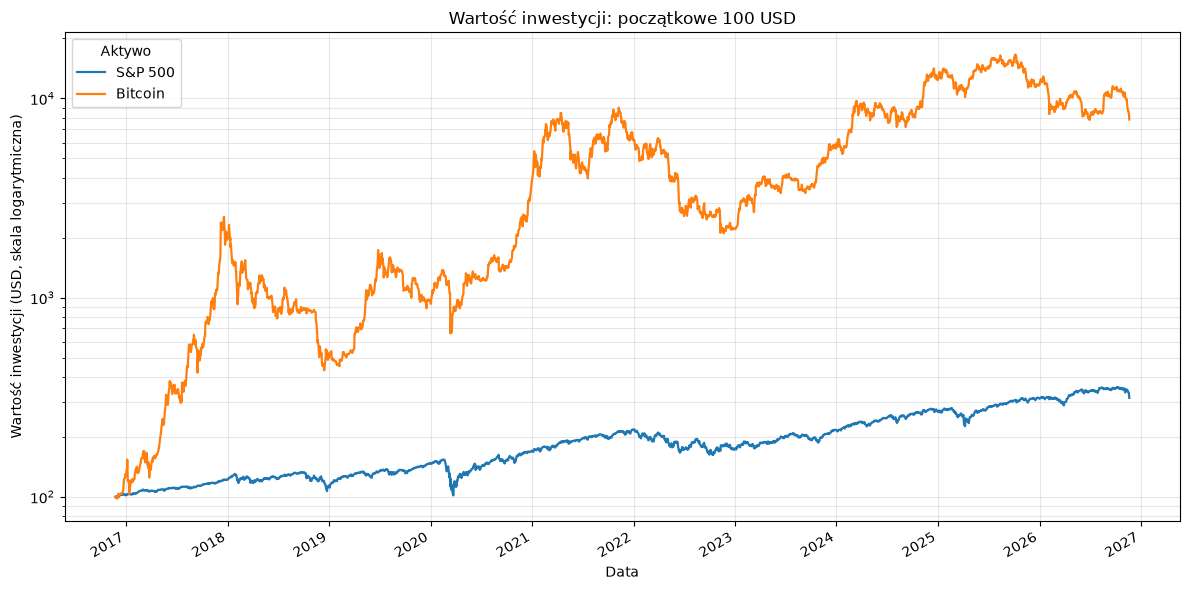

In [36]:
common_prices = prices[ASSETS].dropna().sort_index()
if common_prices.empty:
    raise ValueError("Brak wspólnych dat notowań S&P 500 i BTC.")

normalized_performance = common_prices.div(common_prices.iloc[0]).mul(100)

fig, ax = plt.subplots(figsize=(12, 6))
normalized_performance.rename(columns=ASSET_LABELS).plot(ax=ax, linewidth=1.6)
ax.set_yscale("log")
ax.set_title("Wartość inwestycji: początkowe 100 USD")
ax.set_xlabel("Data")
ax.set_ylabel("Wartość inwestycji (USD, skala logarytmiczna)")
ax.grid(True, which="both", alpha=0.3)
ax.legend(title="Aktywo")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "01_wartosc_inwestycji_100_usd.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 5. Roczna zmienność (Annualized Volatility)

Zmienność pokazuje, jak mocno wahały się dzienne stopy zwrotu. Wartości w pliku CSV są zapisane jako ułamki, dlatego na wykresie formatujemy oś Y jako procenty.

S&P 500 jest annualizowany przez `√252`, a Bitcoin przez `√365`. Pierwszy i ostatni rok w dziesięcioletnim oknie mogą być niepełne.

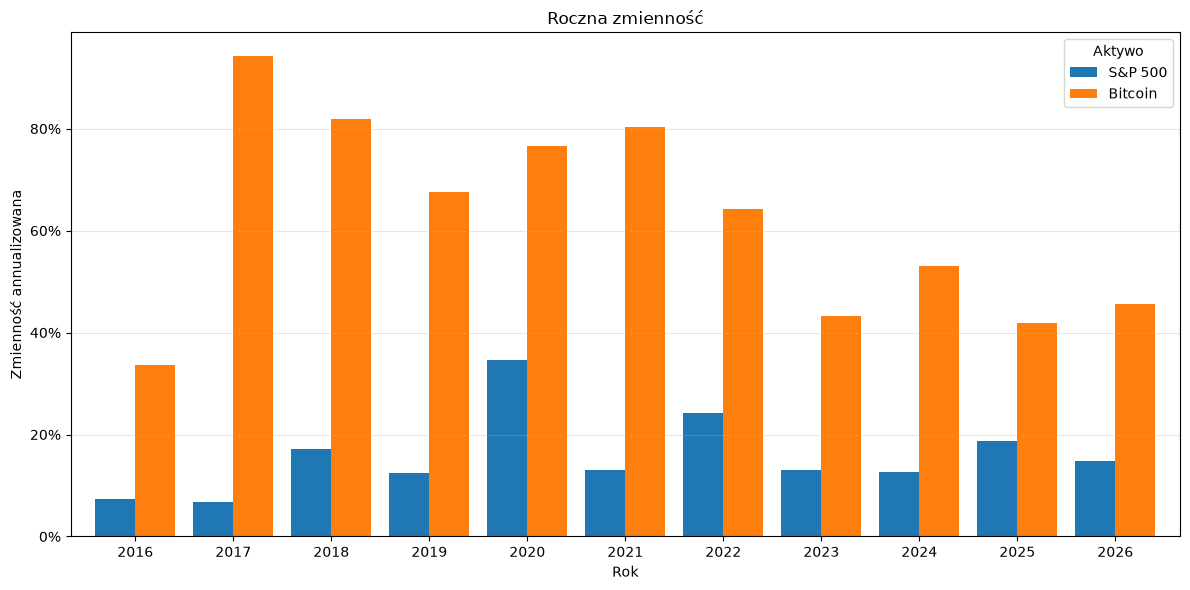

In [37]:
volatility_plot = volatility_by_year[ASSETS].copy()

fig, ax = plt.subplots(figsize=(12, 6))
volatility_plot.rename(columns=ASSET_LABELS).plot(
    kind="bar", ax=ax, width=0.82
)
ax.set_title("Roczna zmienność")
ax.set_xlabel("Rok")
ax.set_ylabel("Zmienność annualizowana")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(True, axis="y", alpha=0.3)
ax.legend(title="Aktywo")
plt.xticks(rotation=0)
fig.tight_layout()
fig.savefig(CHARTS_DIR / "02_roczna_zmiennosc.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 6. Sharpe Ratio

Sharpe Ratio mierzy nadwyżkowy zwrot przypadający na jednostkę zmienności. Wartość dodatnia oznacza, że średni zwrot przewyższał przyjętą stopę wolną od ryzyka; wartość ujemna — że był od niej niższy.

W naszym projekcie benchmarkiem jest rentowność 3-miesięcznych amerykańskich bonów skarbowych FRED `DGS3MO`, traktowana jako przybliżenie stopy wolnej od ryzyka.

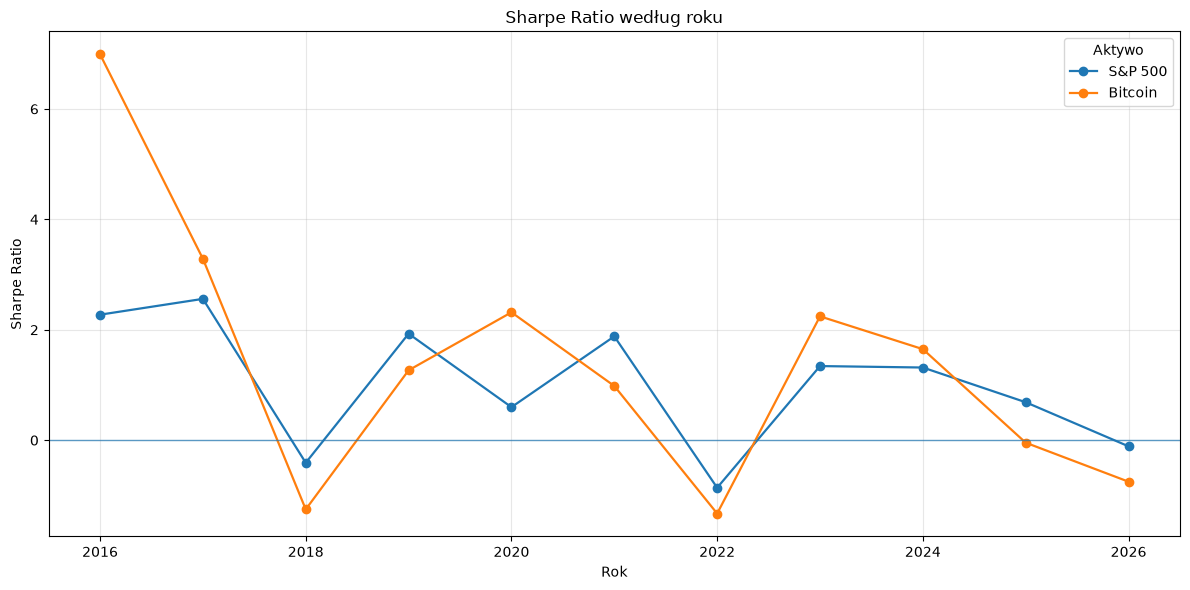

In [38]:
sharpe_plot = sharpe_by_year[ASSETS].copy()

fig, ax = plt.subplots(figsize=(12, 6))
sharpe_plot.rename(columns=ASSET_LABELS).plot(
    ax=ax, marker="o", linewidth=1.6
)
ax.axhline(0, linewidth=1, alpha=0.7)
ax.set_title("Sharpe Ratio według roku")
ax.set_xlabel("Rok")
ax.set_ylabel("Sharpe Ratio")
ax.grid(True, alpha=0.3)
ax.legend(title="Aktywo")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "03_sharpe_ratio.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 7. Historyczny Drawdown

Drawdown pokazuje procentowy spadek od najwyższej wartości osiągniętej wcześniej. Wartość `-0.30` oznacza, że aktywo znajdowało się 30% poniżej wcześniejszego szczytu.

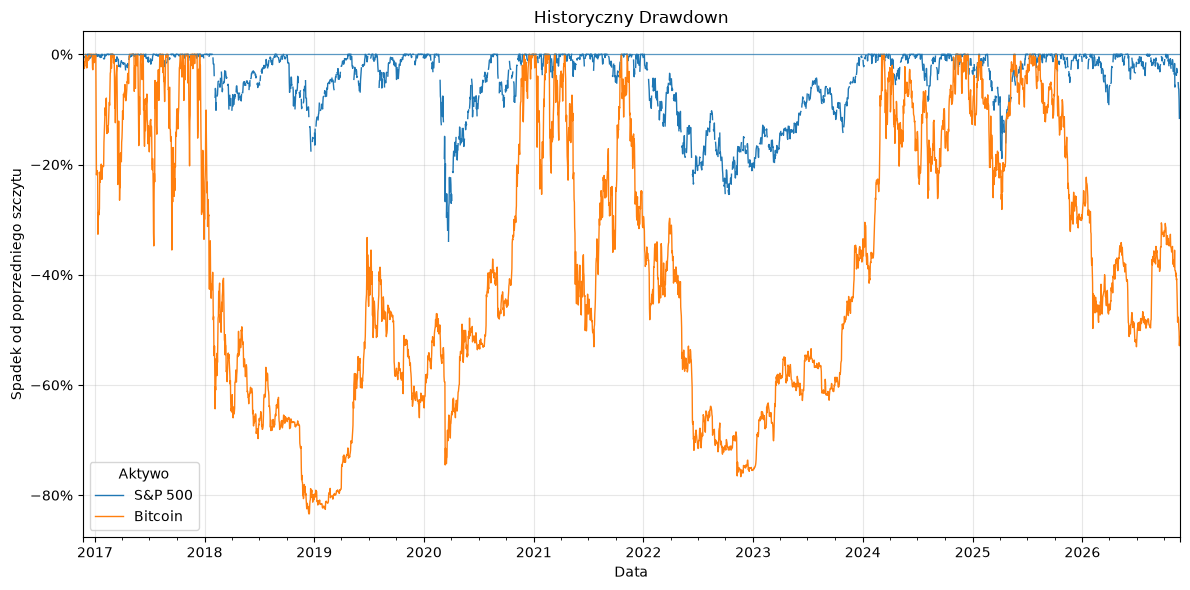

In [39]:
fig, ax = plt.subplots(figsize=(12, 6))
drawdown_series[ASSETS].rename(columns=ASSET_LABELS).plot(
    ax=ax, linewidth=1.0
)
ax.axhline(0, linewidth=0.9, alpha=0.7)
ax.set_title("Historyczny Drawdown")
ax.set_xlabel("Data")
ax.set_ylabel("Spadek od poprzedniego szczytu")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(True, alpha=0.3)
ax.legend(title="Aktywo")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "04_historyczny_drawdown.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 8. Maximum Drawdown według roku

Dla każdego roku szczyt jest liczony od nowa na początku roku. To pokazuje największe obsunięcie **wewnątrz danego roku** i nie musi odpowiadać globalnemu Maximum Drawdown z całej dekady.

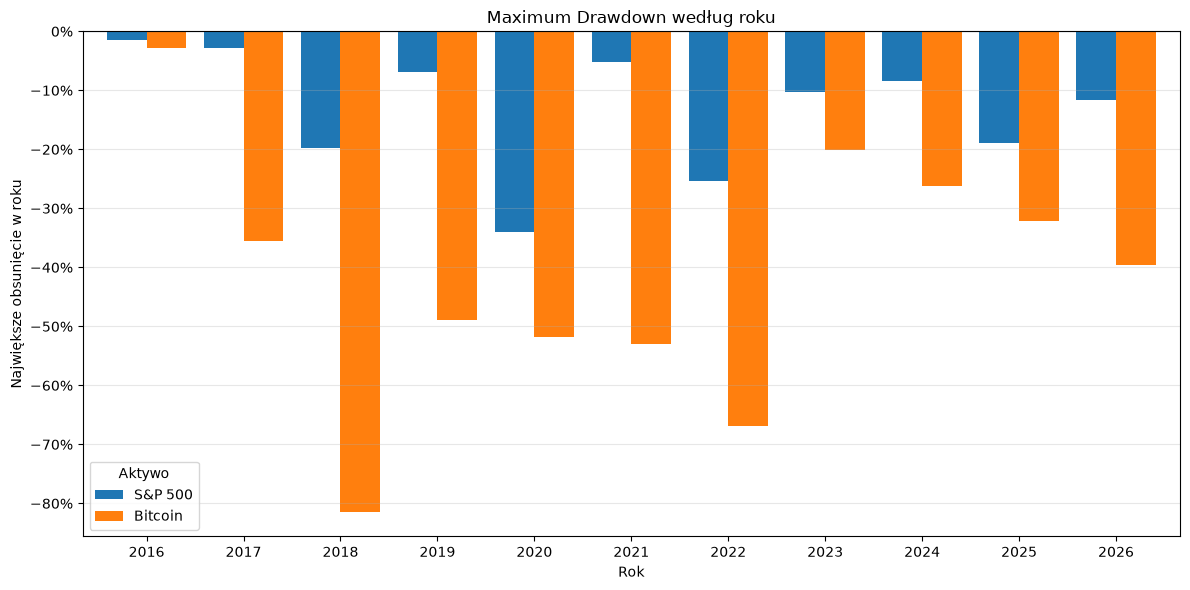

In [40]:
annual_mdd_plot = max_drawdown_by_year[ASSETS].copy()

fig, ax = plt.subplots(figsize=(12, 6))
annual_mdd_plot.rename(columns=ASSET_LABELS).plot(
    kind="bar", ax=ax, width=0.82
)
ax.axhline(0, linewidth=0.8, alpha=0.7)
ax.set_title("Maximum Drawdown według roku")
ax.set_xlabel("Rok")
ax.set_ylabel("Największe obsunięcie w roku")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.grid(True, axis="y", alpha=0.3)
ax.legend(title="Aktywo")
plt.xticks(rotation=0)
fig.tight_layout()
fig.savefig(CHARTS_DIR / "05_roczny_maximum_drawdown.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 9. Korelacja krocząca (90 wspólnych obserwacji)

Korelacja krocząca pokazuje, jak zmieniała się zależność między dziennymi zwrotami S&P 500 i BTC. Okno obejmuje 90 **wspólnych obserwacji**, a nie 90 dni kalendarzowych.

Wartość bliska `+1` oznacza silną dodatnią zależność liniową, bliska `-1` — silną ujemną, a bliska `0` — słabą zależność liniową.

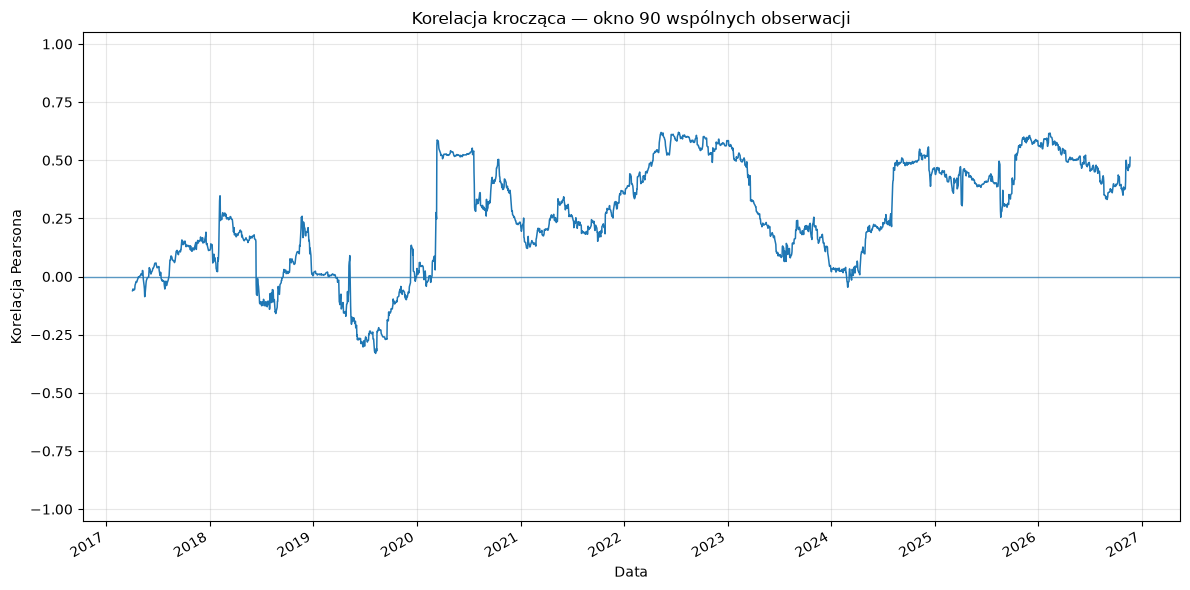

In [41]:
rolling_column = rolling_correlation.columns[0]

fig, ax = plt.subplots(figsize=(12, 6))
rolling_correlation[rolling_column].plot(ax=ax, linewidth=1.1)
ax.axhline(0, linewidth=1, alpha=0.7)
ax.set_ylim(-1.05, 1.05)
ax.set_title("Korelacja krocząca — okno 90 wspólnych obserwacji")
ax.set_xlabel("Data")
ax.set_ylabel("Korelacja Pearsona")
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS_DIR / "06_korelacja_kroczaca_90.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 10. Korelacja według roku

Pokazujemy współczynnik korelacji Pearsona obliczony osobno dla każdego roku. Korelacja opisuje współzmienność liniową — nie dowodzi, że jedno aktywo powoduje ruch drugiego.

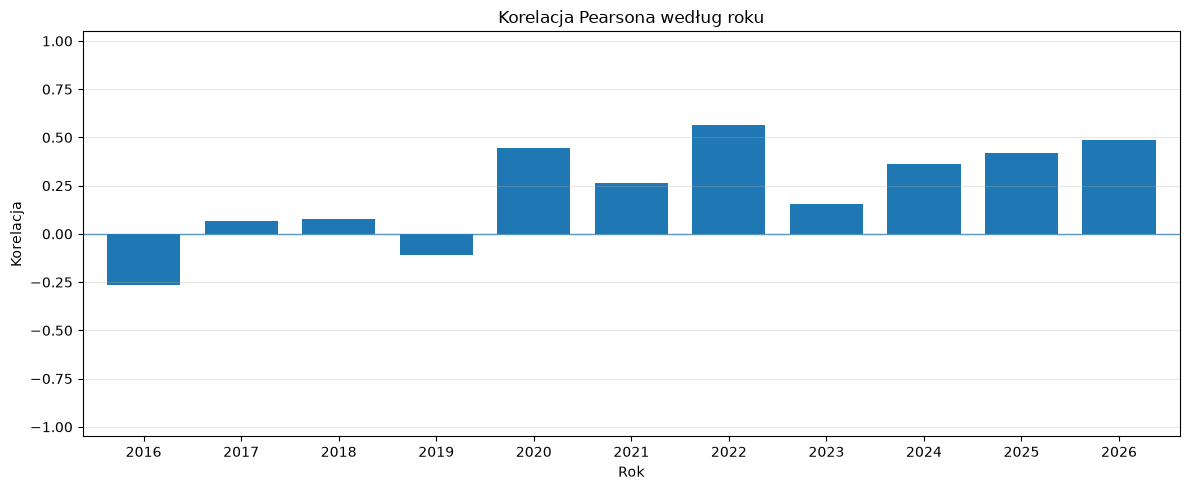

In [42]:
correlation_column = "Pearson Correlation"
if correlation_column not in correlation_by_year.columns:
    raise ValueError(
        f"W correlation_by_year.csv brakuje kolumny '{correlation_column}'."
    )

fig, ax = plt.subplots(figsize=(12, 5))
correlation_by_year[correlation_column].plot(
    kind="bar", ax=ax, width=0.75
)
ax.axhline(0, linewidth=1, alpha=0.7)
ax.set_ylim(-1.05, 1.05)
ax.set_title("Korelacja Pearsona według roku")
ax.set_xlabel("Rok")
ax.set_ylabel("Korelacja")
ax.grid(True, axis="y", alpha=0.3)
plt.xticks(rotation=0)
fig.tight_layout()
fig.savefig(CHARTS_DIR / "07_korelacja_roczna.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 11. Macierz korelacji

Macierz pokazuje korelację dla całego okresu. Na przekątnej znajduje się `1.0`, ponieważ każde aktywo jest doskonale skorelowane samo ze sobą. Interesuje nas przede wszystkim wartość poza przekątną — korelacja S&P 500 z BTC.

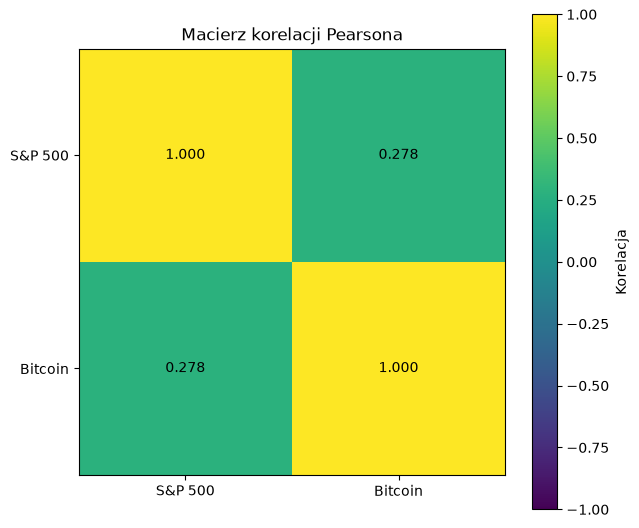

In [43]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(correlation_matrix.values, vmin=-1, vmax=1, aspect="equal")
ax.set_xticks(range(len(ASSETS)), [ASSET_LABELS[a] for a in ASSETS])
ax.set_yticks(range(len(ASSETS)), [ASSET_LABELS[a] for a in ASSETS])
ax.set_title("Macierz korelacji Pearsona")

for row in range(len(ASSETS)):
    for col in range(len(ASSETS)):
        ax.text(
            col, row, f"{correlation_matrix.iloc[row, col]:.3f}",
            ha="center", va="center"
        )

fig.colorbar(image, ax=ax, label="Korelacja")
fig.tight_layout()
fig.savefig(CHARTS_DIR / "08_macierz_korelacji.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 12. Zestawienie najważniejszych wyników

Poniższa tabela zbiera kilka najważniejszych informacji z obliczonych serii. Stopa zmiany wartości inwestycji jest liczona na wspólnych datach i nie uwzględnia dywidend S&P 500.

In [44]:
full_period_summary = pd.DataFrame(index=[ASSET_LABELS[a] for a in ASSETS])
full_period_summary["Zmiana wartości od 100 USD"] = (
    normalized_performance.iloc[-1] / 100 - 1
).reindex(ASSETS).values
full_period_summary["Maximum Drawdown"] = (
    drawdown_series[ASSETS].min().reindex(ASSETS).values
)

full_period_summary = full_period_summary.rename_axis("Aktywo")

print(f"Wspólny zakres dat: {common_prices.index.min().date()} – {common_prices.index.max().date()}")
print(f"Liczba wspólnych obserwacji cen: {len(common_prices):,}")
print(f"Korelacja S&P 500 – BTC: {correlation_matrix.loc['SP500', 'BTC']:.4f}")

display(
    full_period_summary.style.format({
        "Zmiana wartości od 100 USD": "{:.2%}",
        "Maximum Drawdown": "{:.2%}"
    })
)

print("\nWykresy zapisano w:", CHARTS_DIR)

Wspólny zakres dat: 2016-11-22 – 2026-11-20
Liczba wspólnych obserwacji cen: 2,513
Korelacja S&P 500 – BTC: 0.2782


,Zmiana wartości od 100 USD,Maximum Drawdown
Aktywo,,
S&P 500,213.69%,-33.92%
Bitcoin,7725.81%,-83.40%



Wykresy zapisano w: /home/lukaszmusial/programming/projekty/analysis-BTC-vs-spy-return/charts


## 13. Wnioski i ograniczenia

Przed sformułowaniem wniosków porównaj wykresy razem — pojedynczy wskaźnik nie opisuje całego ryzyka inwestycji.

- **Zmienność** opisuje skalę wahań zwrotów, ale nie mówi, w którą stronę nastąpi ruch.
- **Sharpe Ratio** zestawia nadwyżkowy zwrot ze zmiennością; zależy m.in. od przyjętej stopy wolnej od ryzyka.
- **Maximum Drawdown** pokazuje najgłębsze historyczne obsunięcie od szczytu.
- **Korelacja** opisuje zależność liniową i może zmieniać się w czasie.

Ograniczenia analizy:
1. `^GSPC` jest indeksem cenowym — nie uwzględnia dywidend.
2. FRED `DGS3MO` to rentowność referencyjna użyta jako przybliżenie stopy wolnej od ryzyka, a nie bezpośrednio zrealizowany zwrot z konkretnego bonu.
3. Pierwszy i ostatni rok w dziesięcioletnim oknie mogą być niepełne.
4. Wyniki historyczne nie gwarantują podobnych wyników w przyszłości.
5. Korelacja nie oznacza przyczynowości.

**Wszystkie wykresy PNG znajdują się w katalogu `charts/` i mogą zostać osadzone w README na GitHubie.**